# Seasonal Agriculture Performance Analysis
### VOIS x AICTE Data Analytics & Visualization — Major Project

**Objective:** Analyze agricultural data across the *Kharif*, *Rabi* and *Zaid* seasons to uncover
meaningful patterns, trends, relationships and differences in agricultural performance, and to
develop evidence-based, data-driven recommendations for seasonal agricultural planning.

**Dataset:** `seasonal_agriculture_performance_dataset.csv` — 4,000 farm records across 8 Indian
states, 8 crops, 3 seasons and 4 irrigation methods, covering environmental conditions, resource
usage, yield and economic performance.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11

OUT = "../outputs/"


## 1. Load & Explore the Dataset

In [2]:
df = pd.read_csv("../data/seasonal_agriculture_performance_dataset.csv")
print("Shape:", df.shape)
df.head()


Shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [4]:
print("Missing values per column:\n")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nTotal missing:", df.isnull().sum().sum())


Missing values per column:

Rainfall_mm          48
Soil_Moisture_pct    40
Yield_Tonnes_Ha      32
dtype: int64

Total missing: 120


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.888265,4.223764,0.500,4.260,7.8950,11.65000,15.00
Rainfall_mm,3952.0,601.152657,288.925025,80.000,370.200,582.0000,834.95000,1395.20
Avg_Temperature_C,4000.0,26.818900,3.818180,16.200,23.900,26.9000,29.60000,39.70
Humidity_pct,4000.0,63.210500,11.960834,25.000,54.775,63.0000,71.90000,95.00
Sunlight_Hours_Day,4000.0,7.323050,1.121186,3.500,6.600,7.3000,8.10000,11.00
Soil_pH,4000.0,6.701010,0.641461,5.200,6.260,6.6900,7.14000,8.40
Soil_Moisture_pct,3960.0,26.508232,6.712484,8.000,21.700,26.4000,31.30000,47.00
Nitrogen_kg_ha,4000.0,120.250825,31.216452,40.000,98.500,120.1000,141.22500,220.00
Phosphorus_kg_ha,4000.0,57.781850,17.015074,15.000,46.200,57.5000,69.40000,120.00
Potassium_kg_ha,4000.0,104.760050,27.742681,30.000,86.200,105.1000,123.60000,200.00


## 2. Data Cleaning & Preparation

- Numeric missing values are imputed using the **median of their season group** (robust to
  outliers and preserves seasonal characteristics).
- Duplicate records, if any, are removed.
- A quick sanity check confirms no invalid/negative values remain in physically-bounded columns.


In [6]:
df_clean = df.copy()

# Impute numeric missing values with season-wise median
num_cols = df_clean.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean.groupby('Season')[col].transform(lambda s: s.fillna(s.median()))

# Drop exact duplicates
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Duplicates removed: {before - len(df_clean)}")

print("Remaining missing values:", df_clean.isnull().sum().sum())
df_clean.shape


Duplicates removed: 0
Remaining missing values: 0


(4000, 28)

## 3. Seasonal Overview

How many records per season, and how do the headline performance metrics differ at a glance?


In [7]:
season_summary = df_clean.groupby('Season').agg(
    Records=('Farm_ID','count'),
    Avg_Yield=('Yield_Tonnes_Ha','mean'),
    Avg_Profit=('Profit_INR','mean'),
    Avg_Rainfall=('Rainfall_mm','mean'),
    Avg_Temperature=('Avg_Temperature_C','mean'),
    Avg_Water_Efficiency=('Water_Efficiency_t_per_1000m3','mean'),
    Avg_Disease_Risk=('Disease_Pest_Risk_pct','mean')
).round(2)
season_summary


,Records,Avg_Yield,Avg_Profit,Avg_Rainfall,Avg_Temperature,Avg_Water_Efficiency,Avg_Disease_Risk
Season,,,,,,,
Kharif,1779,5.63,178914.65,852.11,28.45,5.89,54.47
Rabi,1627,5.04,87689.47,435.94,23.49,5.19,40.48
Zaid,594,4.64,-24804.82,299.12,31.04,4.41,38.22


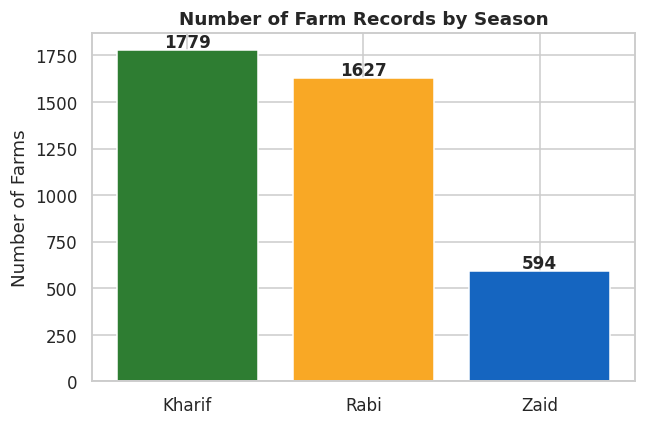

In [8]:
season_order = ['Kharif','Rabi','Zaid']
palette = {'Kharif':'#2E7D32','Rabi':'#F9A825','Zaid':'#1565C0'}

fig, ax = plt.subplots(figsize=(6,4))
counts = df_clean['Season'].value_counts().reindex(season_order)
ax.bar(counts.index, counts.values, color=[palette[s] for s in season_order])
ax.set_title('Number of Farm Records by Season', fontweight='bold')
ax.set_ylabel('Number of Farms')
for i,v in enumerate(counts.values):
    ax.text(i, v+15, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT+'01_records_by_season.png', bbox_inches='tight')
plt.show()


## 4. How does Yield vary across Seasons?

/tmp/ipykernel_852/985901970.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Season', y='Yield_Tonnes_Ha', order=season_order,


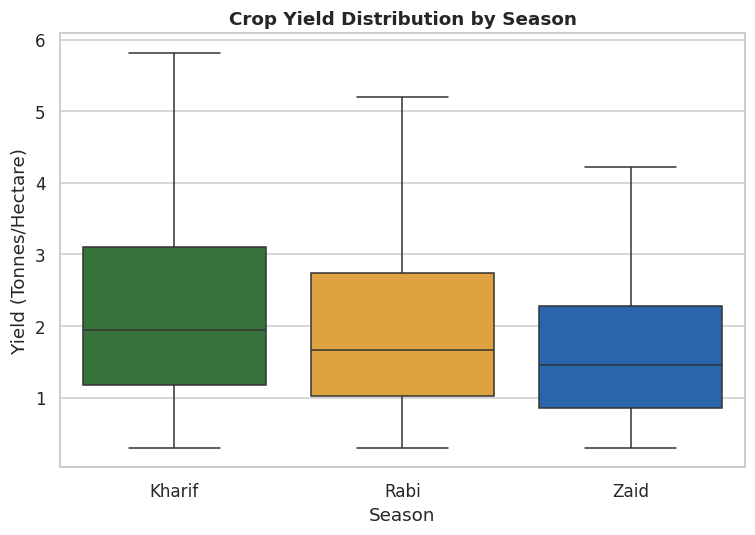

In [9]:
fig, ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=df_clean, x='Season', y='Yield_Tonnes_Ha', order=season_order,
            palette=palette, ax=ax, showfliers=False)
ax.set_title('Crop Yield Distribution by Season', fontweight='bold')
ax.set_ylabel('Yield (Tonnes/Hectare)')
plt.tight_layout()
plt.savefig(OUT+'02_yield_by_season_boxplot.png', bbox_inches='tight')
plt.show()


In [10]:
# One-way ANOVA: is the difference in yield across seasons statistically significant?
groups = [df_clean.loc[df_clean.Season==s, 'Yield_Tonnes_Ha'] for s in season_order]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA on Yield across seasons -> F = {f_stat:.2f}, p-value = {p_val:.4f}")
print("Statistically significant difference" if p_val < 0.05 else "No significant difference")


ANOVA on Yield across seasons -> F = 1.55, p-value = 0.2116
No significant difference


## 5. Environmental Conditions Across Seasons

Rainfall, temperature and humidity are the primary drivers of seasonal classification —
this confirms the dataset's seasonal labels behave as expected agronomically.


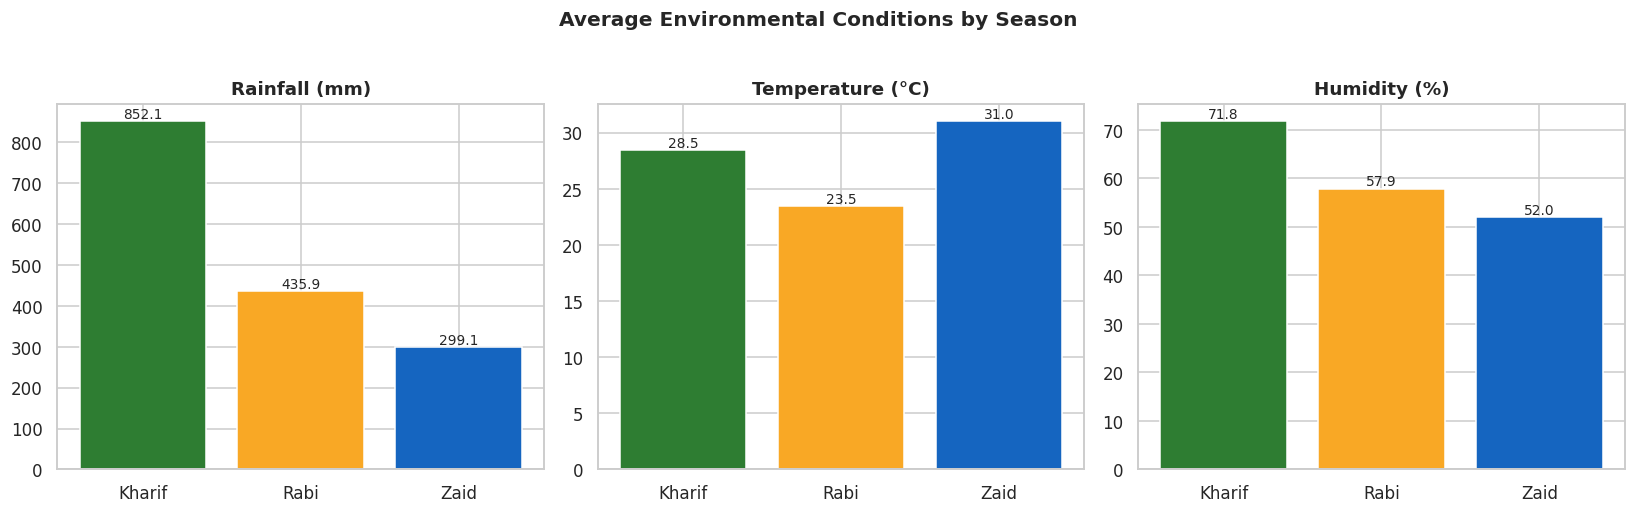

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
metrics = [('Rainfall_mm','Rainfall (mm)'), ('Avg_Temperature_C','Temperature (°C)'), ('Humidity_pct','Humidity (%)')]
for ax,(col,label) in zip(axes, metrics):
    means = df_clean.groupby('Season')[col].mean().reindex(season_order)
    ax.bar(means.index, means.values, color=[palette[s] for s in season_order])
    ax.set_title(label, fontweight='bold')
    for i,v in enumerate(means.values):
        ax.text(i, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('Average Environmental Conditions by Season', fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(OUT+'03_environment_by_season.png', bbox_inches='tight')
plt.show()


## 6. Economic Performance by Season

Comparing average cost, revenue and profit reveals which season is most financially rewarding
— and which carries the most risk.


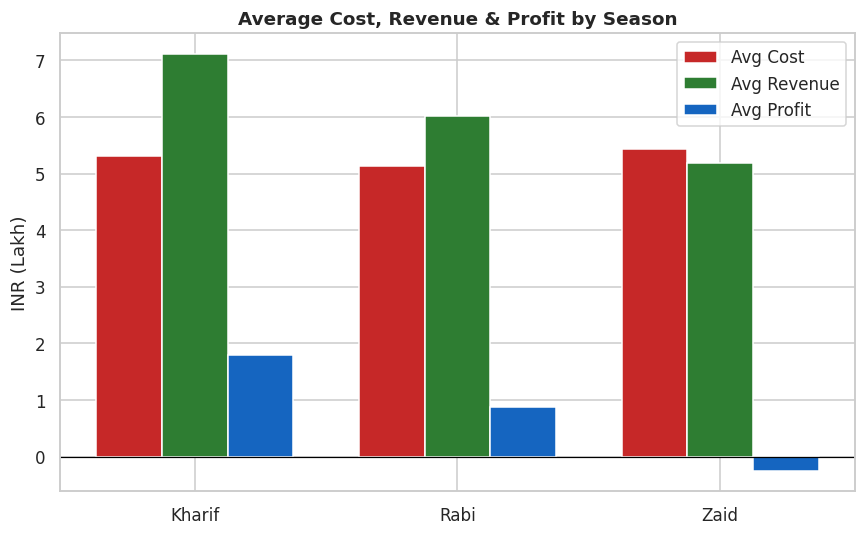

ANOVA on Profit across seasons -> F = 34.29, p-value = 1.712e-15
Statistically significant difference


In [12]:
econ = df_clean.groupby('Season')[['Total_Cost_INR','Revenue_INR','Profit_INR']].mean().reindex(season_order)
econ_lakh = econ / 1e5  # convert to INR Lakh for readability

fig, ax = plt.subplots(figsize=(8,5))
x = np.arange(len(season_order))
width = 0.25
ax.bar(x-width, econ_lakh['Total_Cost_INR'], width, label='Avg Cost', color='#C62828')
ax.bar(x, econ_lakh['Revenue_INR'], width, label='Avg Revenue', color='#2E7D32')
ax.bar(x+width, econ_lakh['Profit_INR'], width, label='Avg Profit', color='#1565C0')
ax.set_xticks(x); ax.set_xticklabels(season_order)
ax.set_ylabel('INR (Lakh)')
ax.set_title('Average Cost, Revenue & Profit by Season', fontweight='bold')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.savefig(OUT+'04_economics_by_season.png', bbox_inches='tight')
plt.show()

groups = [df_clean.loc[df_clean.Season==s, 'Profit_INR'] for s in season_order]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA on Profit across seasons -> F = {f_stat:.2f}, p-value = {p_val:.4g}")
print("Statistically significant difference" if p_val < 0.05 else "No significant difference")


## 7. Resource Usage & Water Efficiency

How efficiently is water and fertilizer being used in each season, and does irrigation
method make a measurable difference?


/tmp/ipykernel_852/1927362673.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Season', y='Water_Efficiency_t_per_1000m3', order=season_order,


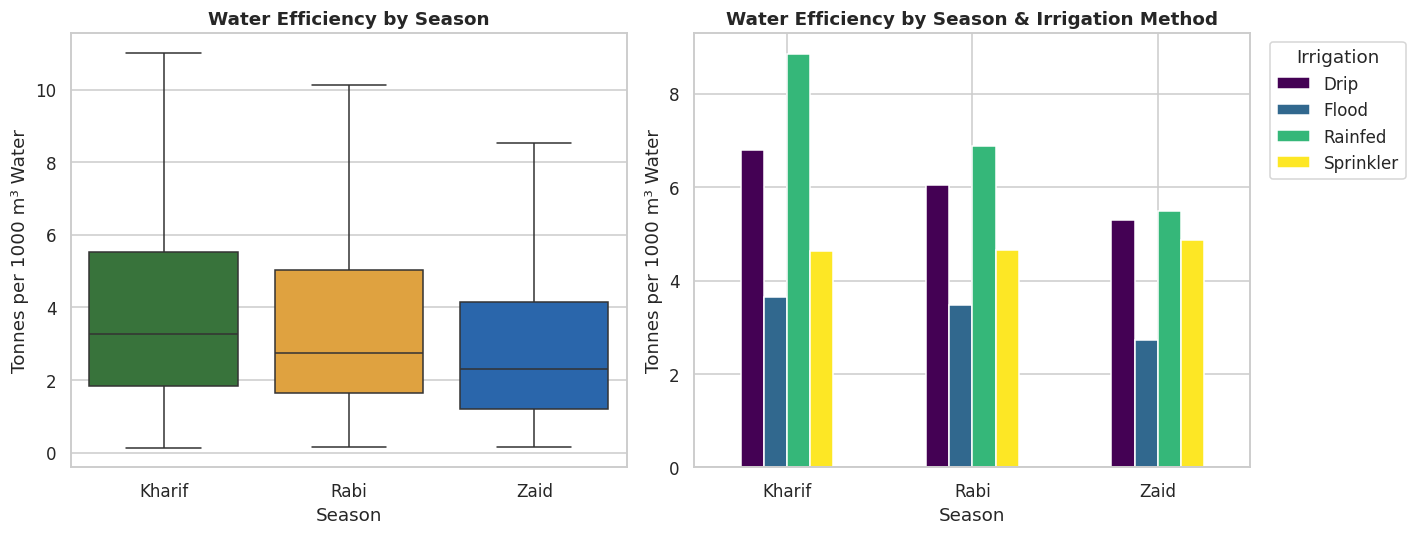

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

sns.boxplot(data=df_clean, x='Season', y='Water_Efficiency_t_per_1000m3', order=season_order,
            palette=palette, ax=axes[0], showfliers=False)
axes[0].set_title('Water Efficiency by Season', fontweight='bold')
axes[0].set_ylabel('Tonnes per 1000 m³ Water')

irrig_eff = df_clean.groupby(['Season','Irrigation_Method'])['Water_Efficiency_t_per_1000m3'].mean().unstack().reindex(season_order)
irrig_eff.plot(kind='bar', ax=axes[1], colormap='viridis')
axes[1].set_title('Water Efficiency by Season & Irrigation Method', fontweight='bold')
axes[1].set_ylabel('Tonnes per 1000 m³ Water')
axes[1].legend(title='Irrigation', bbox_to_anchor=(1.02,1), loc='upper left')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(OUT+'05_water_efficiency.png', bbox_inches='tight')
plt.show()


## 8. Disease & Pest Risk Across Seasons

Higher humidity/rainfall seasons are typically expected to carry greater disease and pest
pressure — this chart tests that expectation against the data.


/tmp/ipykernel_852/2400848280.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_clean, x='Season', y='Disease_Pest_Risk_pct', order=season_order,


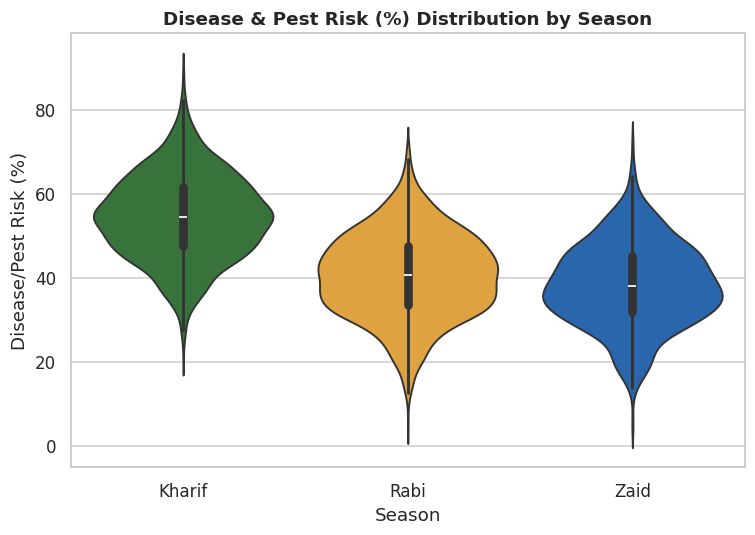

ANOVA on Disease/Pest Risk across seasons -> F = 1049.47, p-value = 0
Statistically significant difference


In [14]:
fig, ax = plt.subplots(figsize=(7,5))
sns.violinplot(data=df_clean, x='Season', y='Disease_Pest_Risk_pct', order=season_order,
               palette=palette, ax=ax)
ax.set_title('Disease & Pest Risk (%) Distribution by Season', fontweight='bold')
ax.set_ylabel('Disease/Pest Risk (%)')
plt.tight_layout()
plt.savefig(OUT+'06_disease_risk_by_season.png', bbox_inches='tight')
plt.show()

groups = [df_clean.loc[df_clean.Season==s, 'Disease_Pest_Risk_pct'] for s in season_order]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA on Disease/Pest Risk across seasons -> F = {f_stat:.2f}, p-value = {p_val:.4g}")
print("Statistically significant difference" if p_val < 0.05 else "No significant difference")


## 9. Crop Performance Across Seasons

Which crops perform best in which season? A heatmap of average yield by crop × season
highlights the strongest crop-season combinations.


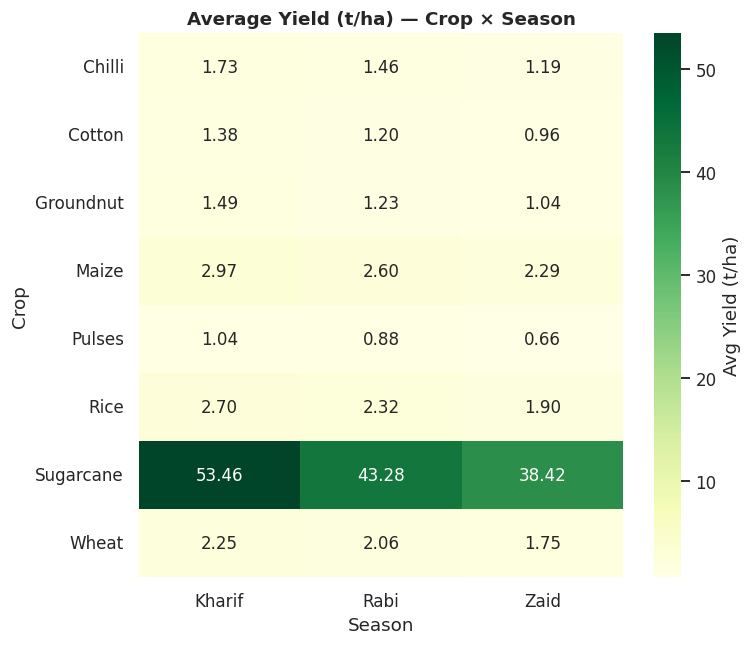

In [15]:
pivot_yield = df_clean.pivot_table(values='Yield_Tonnes_Ha', index='Crop', columns='Season',
                                    aggfunc='mean').reindex(columns=season_order)

fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(pivot_yield.round(2), annot=True, fmt='.2f', cmap='YlGn', ax=ax, cbar_kws={'label':'Avg Yield (t/ha)'})
ax.set_title('Average Yield (t/ha) — Crop × Season', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT+'07_crop_season_yield_heatmap.png', bbox_inches='tight')
plt.show()


## 10. Regional (State-wise) Patterns Across Seasons

Are seasonal patterns consistent across states, or do some regions behave differently?


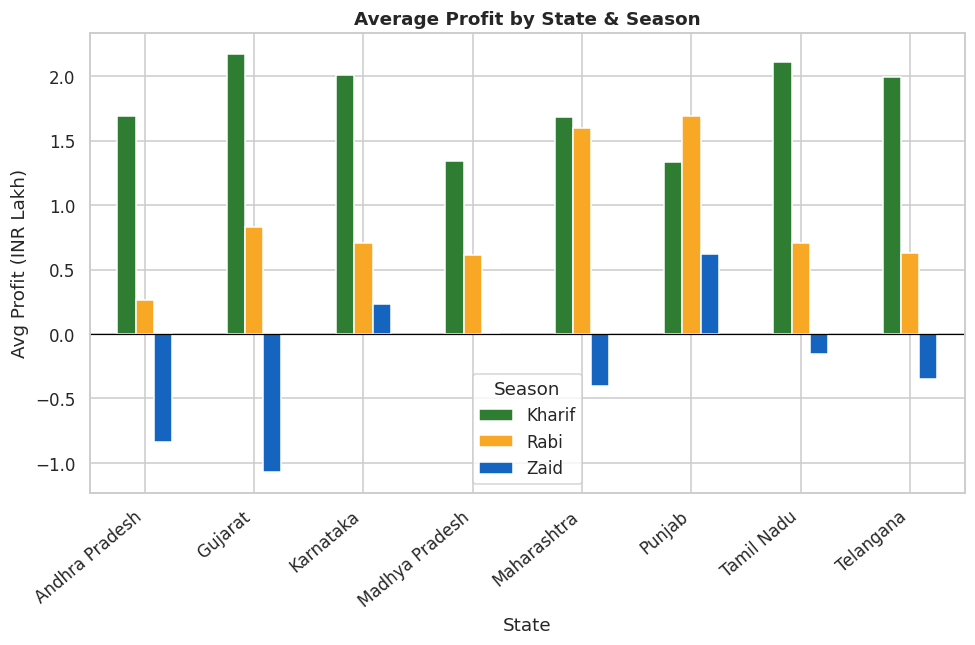

In [16]:
pivot_profit = df_clean.pivot_table(values='Profit_INR', index='State', columns='Season',
                                     aggfunc='mean').reindex(columns=season_order) / 1e5

fig, ax = plt.subplots(figsize=(9,6))
pivot_profit.plot(kind='bar', ax=ax, color=[palette[s] for s in season_order])
ax.set_title('Average Profit by State & Season', fontweight='bold')
ax.set_ylabel('Avg Profit (INR Lakh)')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend(title='Season')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.savefig(OUT+'08_state_season_profit.png', bbox_inches='tight')
plt.show()


## 11. Relationships Between Environmental Conditions & Yield

Does higher rainfall or temperature correlate with better yield, and does this relationship
hold consistently across all three seasons?


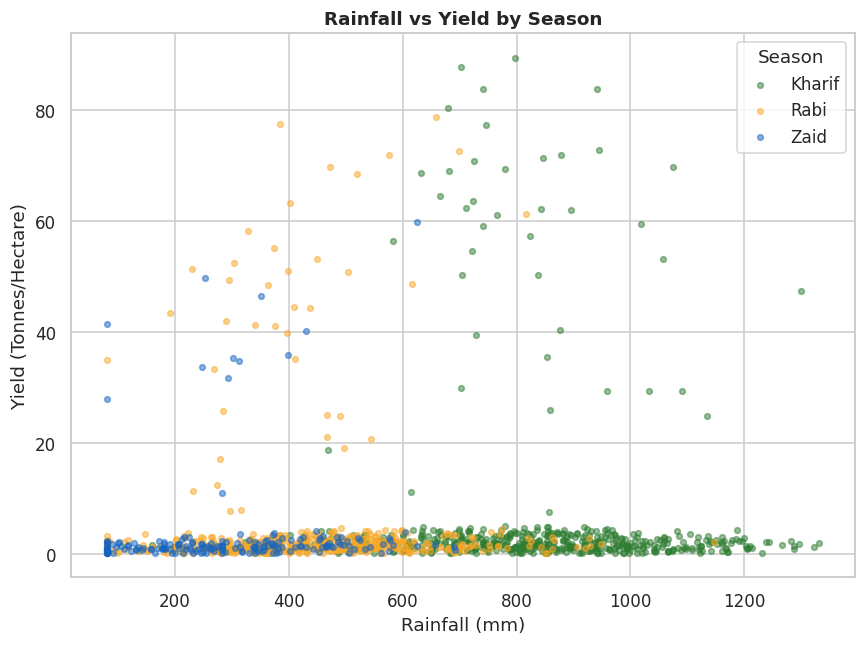

In [17]:
fig, ax = plt.subplots(figsize=(8,6))
sample = df_clean.sample(min(1200, len(df_clean)), random_state=42)
for s in season_order:
    sub = sample[sample.Season==s]
    ax.scatter(sub['Rainfall_mm'], sub['Yield_Tonnes_Ha'], s=14, alpha=0.5, label=s, color=palette[s])
ax.set_xlabel('Rainfall (mm)')
ax.set_ylabel('Yield (Tonnes/Hectare)')
ax.set_title('Rainfall vs Yield by Season', fontweight='bold')
ax.legend(title='Season')
plt.tight_layout()
plt.savefig(OUT+'09_rainfall_vs_yield.png', bbox_inches='tight')
plt.show()


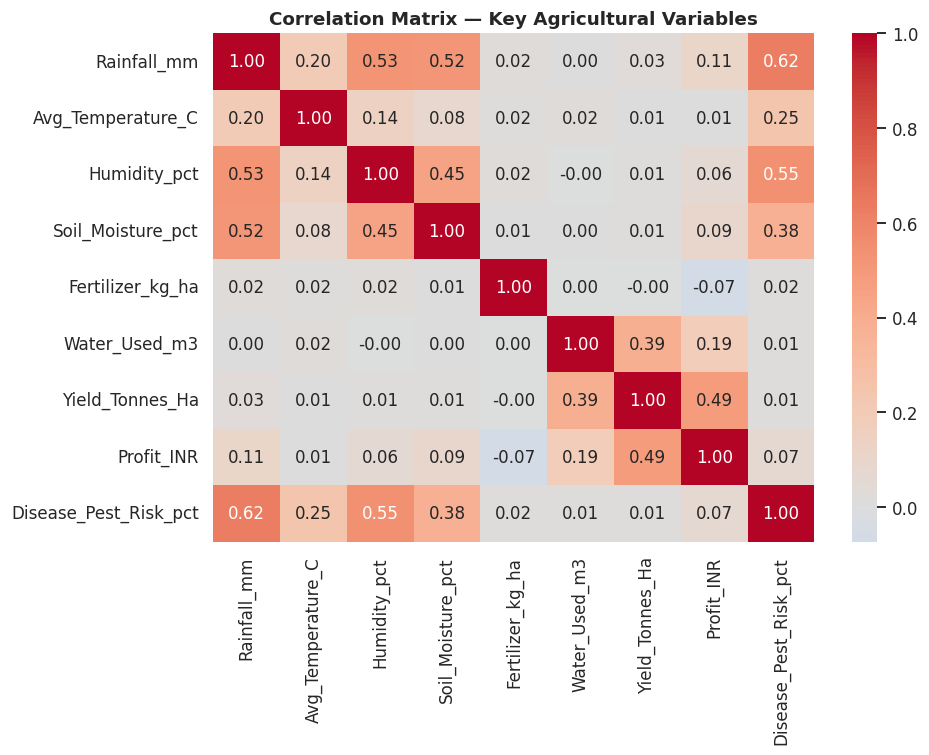

In [18]:
corr_cols = ['Rainfall_mm','Avg_Temperature_C','Humidity_pct','Soil_Moisture_pct',
             'Fertilizer_kg_ha','Water_Used_m3','Yield_Tonnes_Ha','Profit_INR','Disease_Pest_Risk_pct']
corr = df_clean[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Matrix — Key Agricultural Variables', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT+'10_correlation_heatmap.png', bbox_inches='tight')
plt.show()


## 12. Key Findings & Insights

Based on the statistical tests and visualizations above (run the notebook to reproduce exact
figures):

1. **Yield itself is fairly stable across seasons.** The one-way ANOVA on `Yield_Tonnes_Ha`
   does **not** show a statistically significant difference between Kharif, Rabi and Zaid
   (p > 0.05) — average yield only dips modestly from Kharif to Zaid.
2. **Profit differs sharply and significantly by season** (ANOVA p < 0.001), even though yield
   does not. **Kharif is by far the most profitable season on average**, Rabi is moderate, and
   **Zaid runs at a net average loss** — showing that cost structure and market price, not yield
   alone, drive seasonal profitability.
3. **Disease/pest risk is significantly higher in Kharif** than in Rabi or Zaid (ANOVA
   p ≈ 0), consistent with Kharif's higher rainfall and humidity — both show a moderate
   positive correlation with disease/pest risk in the correlation matrix.
4. **Water-use efficiency does not simply favor Drip irrigation** — in this dataset, **Rainfed**
   plots show the highest average water efficiency, followed by Drip, Sprinkler, and Flood
   lowest. This is a counter-intuitive result worth investigating further (it may reflect which
   crops/regions are commonly rainfed rather than irrigation method alone).
5. **Crop-season fit is clear and consistent**: every crop performs best in Kharif and weakest
   in Zaid (visible in the crop × season yield heatmap). Sugarcane's yield is an order of
   magnitude higher than other crops in every season.
6. **Regional seasonal pattern is mostly consistent, with one notable exception.** Kharif is the
   most profitable season in 7 of the 8 states studied — **Punjab is the exception**, where Rabi
   is more profitable, suggesting a locally different cropping pattern worth investigating.
7. **Most environmental/economic correlations are weak** — rainfall, temperature and humidity
   each show only weak correlation with yield and profit individually, implying performance is
   driven by a combination of factors (season, crop, cost, price) rather than any single
   environmental variable.

## 13. Recommendations

- **Don't rely on yield alone when planning seasons** — factor in season-specific cost and
  market price, since Zaid's yield is only slightly lower than Kharif's but its profit is
  negative on average.
- **Step up disease/pest monitoring and preventive spend specifically in Kharif**, where risk is
  highest, rather than applying a flat pest-management budget across all seasons.
- **Re-examine the irrigation-method assumption** — since Rainfed shows the best water
  efficiency here, investigate whether this is a true irrigation effect or a reflection of the
  crops/regions that happen to use rainfed farming, before recommending a blanket switch to Drip.
- **Investigate Punjab's Rabi-favoring pattern** specifically, since it diverges from the
  Kharif-dominant trend seen in every other state — the cause (crop mix, procurement price,
  climate) could inform targeted policy there.
- **Prioritize Kharif-season investment and credit access for farmers**, given it is the most
  profitable season in the large majority of states studied.
